In [1]:
# Import the libraries required for our project

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

In [2]:
# Load the CSV file from the project folder

df = pd.read_csv("food-texture.csv")

# Display the first five rows
print("First five rows:")
print(df.head())

First five rows:
  Unnamed: 0   Oil  Density  Crispy  Fracture  Hardness
0       B110  16.5     2955      10        23        97
1       B136  17.7     2660      14         9       139
2       B171  16.2     2870      12        17       143
3       B192  16.7     2920      10        31        95
4       B225  16.3     2975      11        26       143


In [3]:
# Display the number of rows and columns
print("Dataset shape:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns)

# Display data types
print("\nData types:")
print(df.dtypes)

# Display basic statistical information
print("\nStatistical summary:")
print(df.describe())

Dataset shape: (50, 6)

Column names:
Index(['Unnamed: 0', 'Oil', 'Density', 'Crispy', 'Fracture', 'Hardness'], dtype='object')

Data types:
Unnamed: 0     object
Oil           float64
Density         int64
Crispy          int64
Fracture        int64
Hardness        int64
dtype: object

Statistical summary:
             Oil     Density     Crispy   Fracture    Hardness
count  50.000000    50.00000  50.000000  50.000000   50.000000
mean   17.202000  2857.60000  11.520000  20.860000  128.180000
std     1.592007   124.49998   1.775571   5.466073   31.127578
min    13.700000  2570.00000   7.000000   9.000000   63.000000
25%    16.300000  2772.50000  10.000000  17.000000  107.250000
50%    16.900000  2867.50000  12.000000  21.000000  126.000000
75%    18.100000  2945.00000  13.000000  25.000000  143.750000
max    21.200000  3125.00000  15.000000  33.000000  192.000000


In [4]:
# Check the number of missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

Missing values:
Unnamed: 0    0
Oil           0
Density       0
Crispy        0
Fracture      0
Hardness      0
dtype: int64

Number of duplicate rows:
0


In [5]:
# Remove the sample ID column because it is not a useful
# numerical predictor of crispness

df = df.drop(columns=["Unnamed: 0"])

# Display the remaining columns
print("Columns after removing the ID:")
print(df.columns)

# Display the cleaned dataset
print("\nCleaned dataset:")
print(df.head())

Columns after removing the ID:
Index(['Oil', 'Density', 'Crispy', 'Fracture', 'Hardness'], dtype='object')

Cleaned dataset:
    Oil  Density  Crispy  Fracture  Hardness
0  16.5     2955      10        23        97
1  17.7     2660      14         9       139
2  16.2     2870      12        17       143
3  16.7     2920      10        31        95
4  16.3     2975      11        26       143


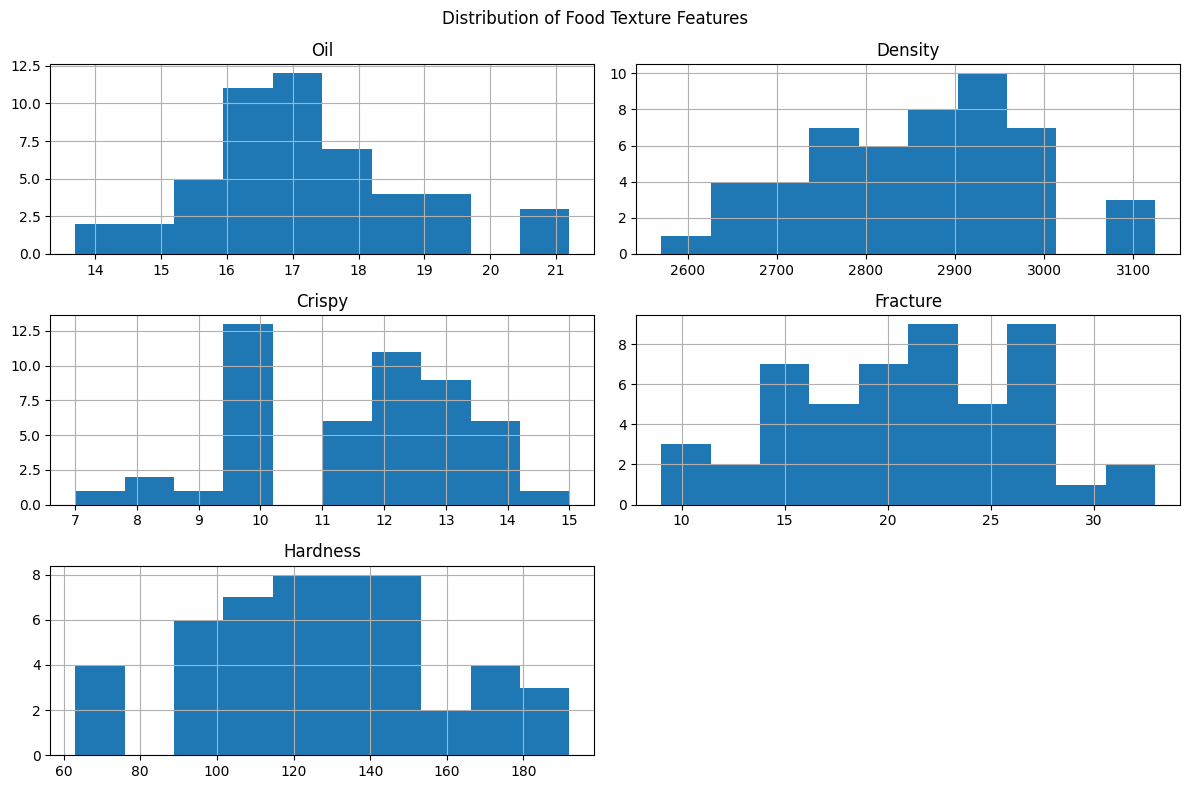

In [6]:
# Plot histograms to understand the distribution of each feature

df.hist(figsize=(12, 8), bins=10)

# Add a title to the complete figure
plt.suptitle("Distribution of Food Texture Features")

# Adjust the layout
plt.tight_layout()

# Display the graphs
plt.show()

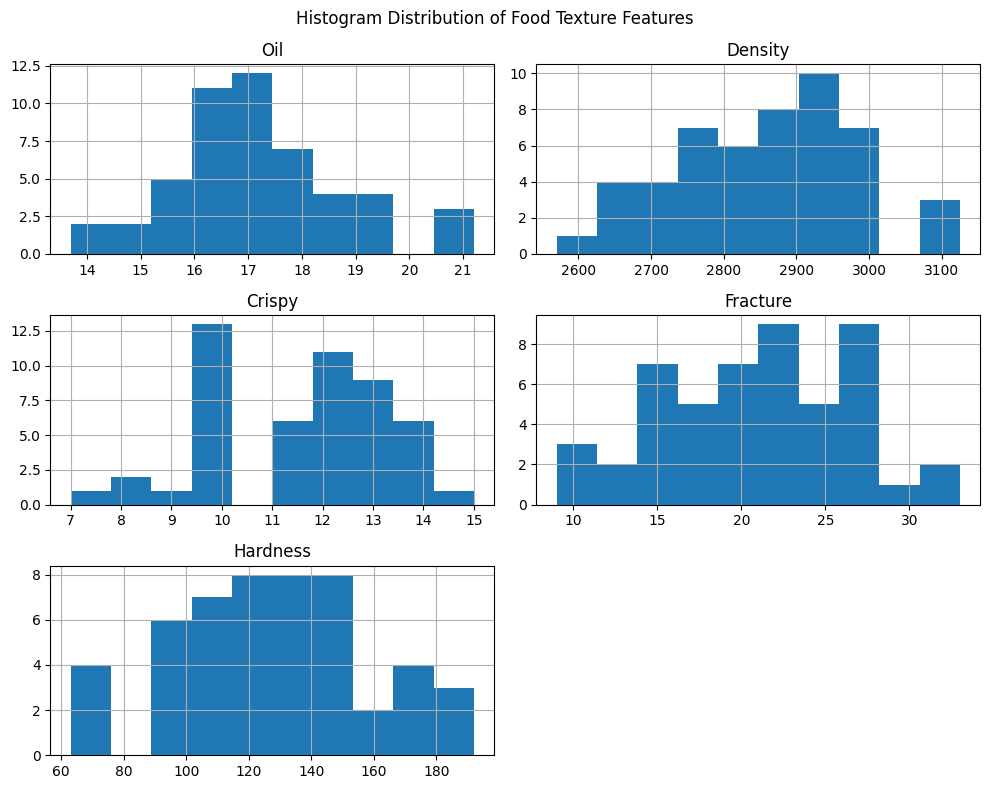

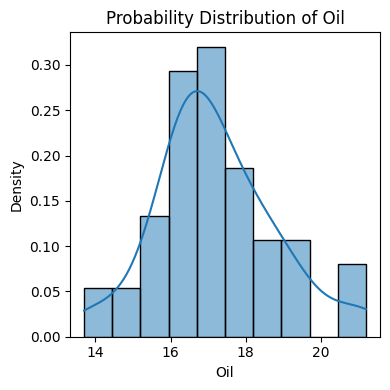

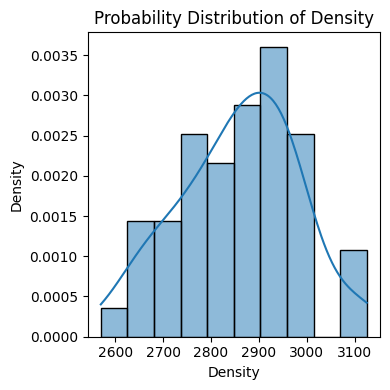

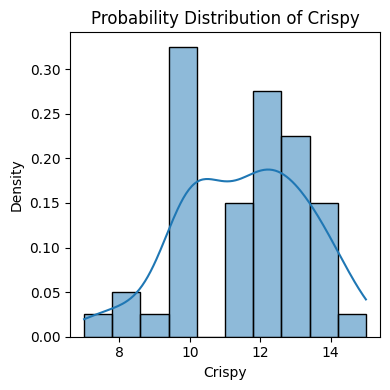

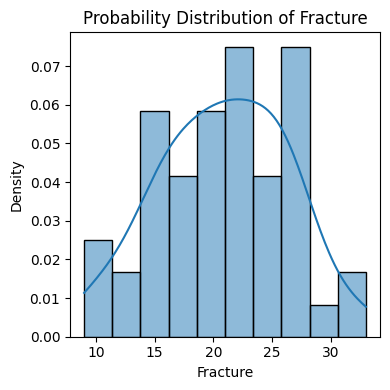

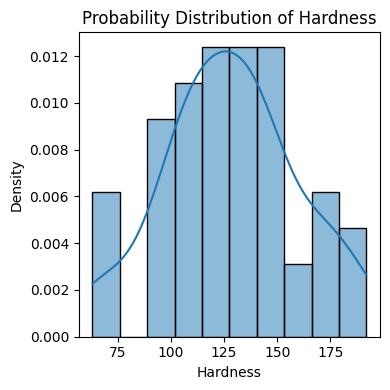

In [27]:
# Plot histograms with probability distribution curves
# for all numerical features in the dataset

# Create a figure with 2 rows and 3 columns
df.hist(figsize=(10, 8), bins=10)

plt.suptitle("Histogram Distribution of Food Texture Features")
plt.tight_layout()
plt.show()

# Plot histogram with KDE curve for each feature separately
for column in df.columns:

    plt.figure(figsize=(4, 4))

    # Histogram shows the distribution of values
    # KDE curve gives a smooth estimate of the distribution
    sns.histplot(
        data=df,
        x=column,
        bins=10,
        kde=True,
        stat="density"
    )

    plt.title("Probability Distribution of " + column)
    plt.xlabel(column)
    plt.ylabel("Density")

    plt.tight_layout()
    plt.show()

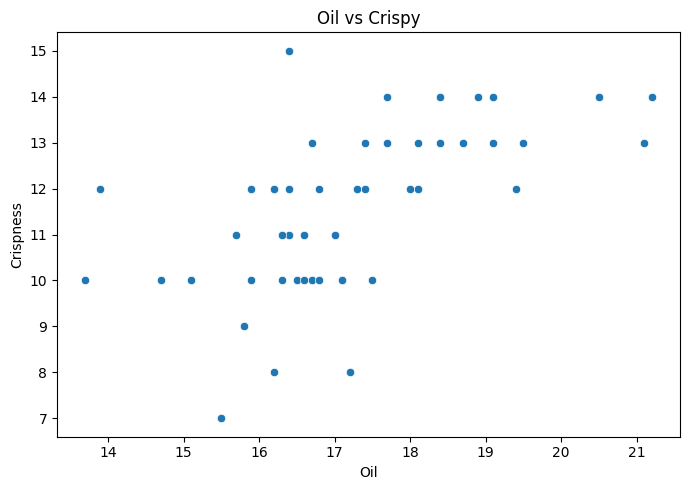

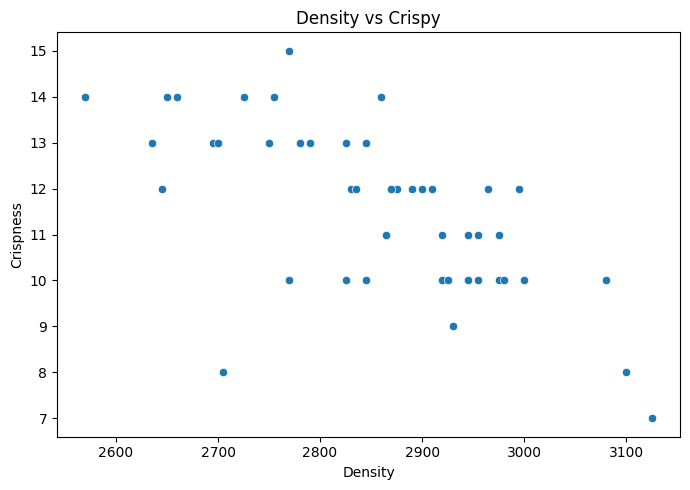

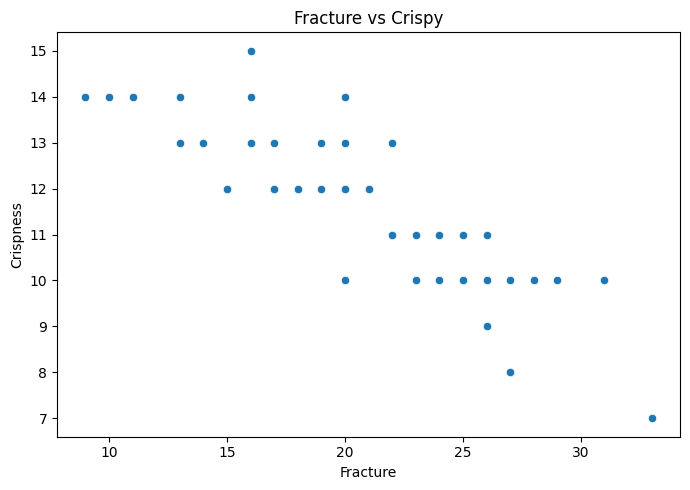

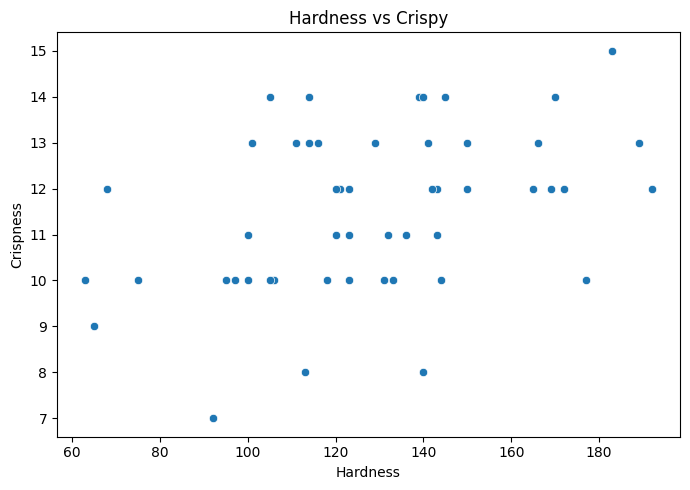

In [ ]:
# Scatter plots to study the relationship between input features
# and the target variable Crispy
#which 2 features have high relationship - scatter plot

# List of input features
features = ["Oil", "Density", "Fracture", "Hardness"]

# Create one scatter plot for each input feature
for column in features:

    plt.figure(figsize=(7, 5))

    # Plot the input feature against the target
    sns.scatterplot(data=df, x=column, y="Crispy")

    # Add title and axis labels
    plt.title(column + " vs Crispy")
    plt.xlabel(column)
    plt.ylabel("Crispness")

    # Display the plot
    plt.tight_layout()
    plt.show()

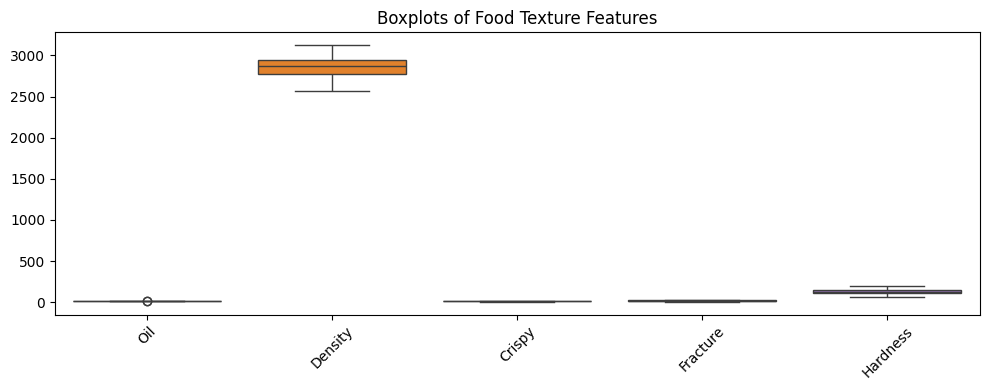

In [8]:
# Create boxplots for all numerical columns

plt.figure(figsize=(10, 4))

sns.boxplot(data=df)

plt.title("Boxplots of Food Texture Features")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
# Calculate the correlation between numerical features

correlation = df.corr()

# Print the correlation values
print(correlation)

               Oil   Density    Crispy  Fracture  Hardness
Oil       1.000000 -0.750024  0.593086 -0.533739 -0.096045
Density  -0.750024  1.000000 -0.670946  0.572132  0.107937
Crispy    0.593086 -0.670946  1.000000 -0.843965  0.411093
Fracture -0.533739  0.572132 -0.843965  1.000000 -0.373358
Hardness -0.096045  0.107937  0.411093 -0.373358  1.000000


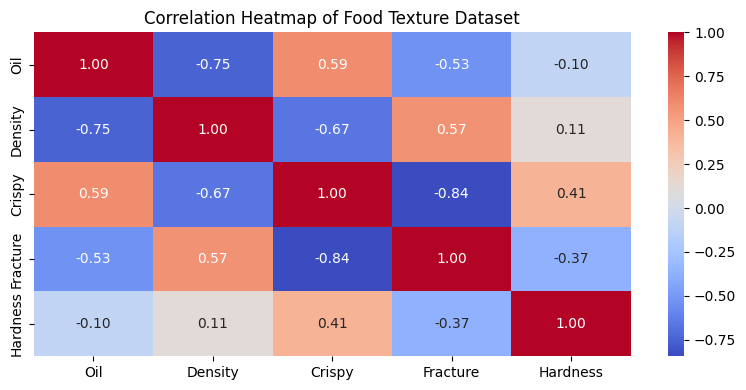

In [ ]:
# Create a heatmap to visualize correlations
#how much it is corelated-heat map analysis

plt.figure(figsize=(8, 4))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Food Texture Dataset")

plt.tight_layout()
plt.show()

In [12]:
# Select four input features
X = df[["Oil", "Density", "Fracture", "Hardness"]]

# Select the target variable
y = df["Crispy"]

# Display the input features
print("Input features:")
print(X.head())

# Display the target values
print("\nTarget values:")
print(y.head())

# Display the dimensions
print("\nInput shape:", X.shape)
print("Target shape:", y.shape)

Input features:
    Oil  Density  Fracture  Hardness
0  16.5     2955        23        97
1  17.7     2660         9       139
2  16.2     2870        17       143
3  16.7     2920        31        95
4  16.3     2975        26       143

Target values:
0    10
1    14
2    12
3    10
4    11
Name: Crispy, dtype: int64

Input shape: (50, 4)
Target shape: (50,)


In [13]:
# Split the data into 80% training and 20% testing

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Display the number of samples in each set
print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (40, 4)
Testing input shape: (10, 4)
Training target shape: (40,)
Testing target shape: (10,)


In [14]:
# Create the linear regression model
model = LinearRegression()

# Train the model using the training data
model.fit(X_train, y_train)

print("Linear Regression model trained successfully")

Linear Regression model trained successfully


In [15]:
# Predict crispness for the test data

y_pred = model.predict(X_test)

# Display actual and predicted values
results = pd.DataFrame({
    "Actual Crispy": y_test.values,
    "Predicted Crispy": y_pred
})

print(results)

   Actual Crispy  Predicted Crispy
0             12         11.400733
1             10          9.745948
2             10          9.646593
3             11         10.597473
4             12         12.253810
5             13         13.530983
6             10          9.941802
7             12         12.913048
8              7          7.542662
9             14         14.269877


In [16]:
# Calculate evaluation metrics

r2 = r2_score(y_test, y_pred)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = mse ** 0.5

# Display the results
print("Model Evaluation Results")
print("------------------------")
print("R2 Score:", round(r2, 4))
print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))

Model Evaluation Results
------------------------
R2 Score: 0.9352
MAE: 0.4178
MSE: 0.2261
RMSE: 0.4755


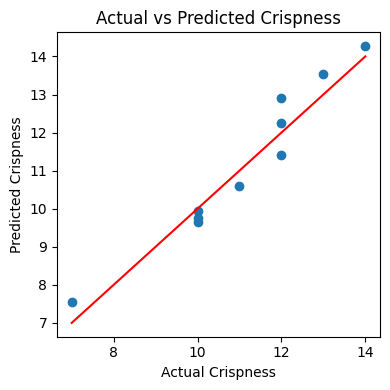

In [21]:
# Compare actual crispness values with predicted values

plt.figure(figsize=(4, 4))

plt.scatter(y_test, y_pred)

# Draw a reference line for perfect predictions
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.xlabel("Actual Crispness")
plt.ylabel("Predicted Crispness")

plt.title("Actual vs Predicted Crispness")

plt.tight_layout()
plt.show()

In [22]:
# Display the intercept and coefficient for each input feature

print("Intercept:", model.intercept_)

print("\nFeature Coefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", round(coefficient, 4))

Intercept: 22.13131459980902

Feature Coefficients:
Oil : 0.1833
Density : -0.0043
Fracture : -0.1619
Hardness : 0.0155


In [23]:
# Enter values for a new food sample
oil = float(input("Enter Oil value: "))
density = float(input("Enter Density value: "))
fracture = float(input("Enter Fracture value: "))
hardness = float(input("Enter Hardness value: "))

# Create a DataFrame with the same feature names used during training
new_sample = pd.DataFrame({
    "Oil": [oil],
    "Density": [density],
    "Fracture": [fracture],
    "Hardness": [hardness]
})

# Predict crispness
predicted_crispy = model.predict(new_sample)

print("Predicted Crispness:", round(predicted_crispy[0], 2))

Predicted Crispness: 9.0


In [34]:
#for 2 features

# Select two input features
X_two = df[["Fracture", "Density"]]

# Select the target variable
y_two = df["Crispy"]

print("Input features:", X_two.columns.tolist())
print("Input shape:", X_two.shape)

Input features: ['Fracture', 'Density']
Input shape: (50, 2)


In [35]:
# Split the data into training and testing sets
# Use the same random state as the 4-feature model

X_train_two, X_test_two, y_train_two, y_test_two = train_test_split(
    X_two, y_two, test_size=0.2, random_state=42
)

print("Training shape:", X_train_two.shape)
print("Testing shape:", X_test_two.shape)

Training shape: (40, 2)
Testing shape: (10, 2)


In [36]:
# Create the linear regression model
model_two = LinearRegression()

# Train the model using two input features
model_two.fit(X_train_two, y_train_two)

print("2-feature Linear Regression model trained successfully")

2-feature Linear Regression model trained successfully


In [37]:
# Predict crispness using the test data
y_pred_two = model_two.predict(X_test_two)

# Calculate evaluation metrics
r2_two = r2_score(y_test_two, y_pred_two)
mae_two = mean_absolute_error(y_test_two, y_pred_two)
mse_two = mean_squared_error(y_test_two, y_pred_two)
rmse_two = mse_two ** 0.5

# Display the results
print("2-Feature Model Results")
print("-----------------------")
print("R2 Score:", round(r2_two, 4))
print("MAE:", round(mae_two, 4))
print("MSE:", round(mse_two, 4))
print("RMSE:", round(rmse_two, 4))

2-Feature Model Results
-----------------------
R2 Score: 0.9348
MAE: 0.4102
MSE: 0.2276
RMSE: 0.4771


In [38]:
# Compare the 2-feature and 4-feature models

comparison = pd.DataFrame({
    "Metric": ["R2 Score", "MAE", "MSE", "RMSE"],
    "2 Features": [r2_two, mae_two, mse_two, rmse_two],
    "4 Features": [r2, mae, mse, rmse]
})

print(comparison)

     Metric  2 Features  4 Features
0  R2 Score    0.934788    0.935206
1       MAE    0.410185    0.417783
2       MSE    0.227589    0.226131
3      RMSE    0.477062    0.475532


In [ ]:
#model1 is better since it has higher r2 model2  can also be used interms of simplicity with equal performance
